# 04 · Expression — EMT-transcription-factor readout along the trajectory

Overlay the canonical EMT transcription factors on the trajectory to show which
drivers track the differentiation axis. Under 10x dropout most EMT-TFs are sparsely
detected, so the panel is **detection-gated**: TFs are ranked by detection fraction
and pseudotime gradient. For this noradrenergic neuroblastoma manifold the EMT-TF
readout is **monotone**, not bipolar — only **ZEB1** is substantially detected
(~40% of cells) and it rises weakly toward the neural-crest terminus, while the
canonical mesenchymal drivers (SNAI1/2, TWIST1/2, PRRX1, FOXC1) sit at or below the
detection floor. This is consistent with the near-absent mesenchymal programme
(no MES arm). The honest representation is therefore a **single graded ZEB1 panel**
(the terminus marker), not a two-pole early/late pair. Deliverable: `expression.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Jansky2021_Neuroendocrine | category: Neuroendocrine


### Load signatures manifold and rank EMT-TFs (detection-gated, data-driven)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; rho,_ = spearmanr(tn, x); rows.append((g, (x>0).mean(), rho))
df = pd.DataFrame(rows, columns=['TF','detect_frac','rho_t']).sort_values('rho_t')
print(df.round(3).to_string(index=False))
DET = 0.03  # detection floor (10x dropout)
ok = df[df.detect_frac >= DET].sort_values('detect_frac', ascending=False)
marker = ok.iloc[0]['TF']  # most-detected informative EMT-TF (monotone case)
mrho = float(df[df.TF==marker]['rho_t'].iloc[0]); mdet = float(df[df.TF==marker]['detect_frac'].iloc[0])
print(f'\ndetection floor {DET}: monotone case -> single marker = {marker} (det {mdet:.0%}, rho_t {mrho:+.2f})')

    TF  detect_frac  rho_t
 SNAI2        0.001 -0.007
 PRRX1        0.003 -0.005
 SNAI1        0.001 -0.002
 FOXC1        0.003  0.001
TWIST2        0.001  0.008
 PRRX2        0.014  0.017
TWIST1        0.087  0.024
  ZEB2        0.099  0.028
  ZEB1        0.423  0.088

detection floor 0.03: monotone case -> single marker = ZEB1 (det 42%, rho_t +0.09)


### EMT-TF expression figure (deliverable)
Monotone single-gene house panel (`figsize=(3.5,1.5)`, pseudotime left→right,
`size=30`, plasma), showing the derived terminus marker. This mirrors the
non-branching precedent where one EMT-TF graded along pseudotime is the honest
readout (a two-pole early/late pair would fabricate a mesenchymal early factor that
is not detected here).

saved expression.pdf | ZEB1: det 42%, rho_t +0.09


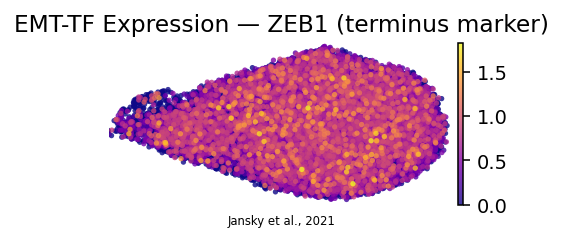

In [4]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
x = np.asarray(adata[:,marker].X.todense()).ravel() if hasattr(adata[:,marker].X,'todense') else np.asarray(adata[:,marker].X).ravel()
det = (x>0).mean(); rho,_ = spearmanr(tn, x)
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color=marker, cmap='plasma', alpha=.8, size=30, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title=f'EMT-TF Expression \u2014 {marker} (terminus marker)')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Jansky et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
print(f'saved expression.pdf | {marker}: det {det:.0%}, rho_t {rho:+.2f}')